

<br><br>

---

# MACHINE LEARNING ZOOMCAMP - ALEXEY GRIGOREV

---

<br>

# MODULE 2: Regression (Exploratory Data Analysis) 

<br><br>

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

<br>


>
>Project Plan:
>
>  - Data Preparation 
>  
>  - Exploratory Data Analysis
>
>  - Setting Up Validation Framework


<br>


<br><br>

---

# 1. Data Preparation

<br>

In [2]:
data = "https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/refs/heads/master/chapter-02-car-price/data.csv"

df = pd.read_csv(data)
df.head()

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


In [3]:
# Let's see the consistency of the data by checking the columns
df.columns

Index(['Make', 'Model', 'Year', 'Engine Fuel Type', 'Engine HP',
       'Engine Cylinders', 'Transmission Type', 'Driven_Wheels',
       'Number of Doors', 'Market Category', 'Vehicle Size', 'Vehicle Style',
       'highway MPG', 'city mpg', 'Popularity', 'MSRP'],
      dtype='str')

In [4]:
# Let's correct the column names by removing the spaces and converting them to lowercase
df.columns = df.columns.str.lower().str.replace(" ", "_")

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11914 entries, 0 to 11913
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   make               11914 non-null  str    
 1   model              11914 non-null  str    
 2   year               11914 non-null  int64  
 3   engine_fuel_type   11911 non-null  str    
 4   engine_hp          11845 non-null  float64
 5   engine_cylinders   11884 non-null  float64
 6   transmission_type  11914 non-null  str    
 7   driven_wheels      11914 non-null  str    
 8   number_of_doors    11908 non-null  float64
 9   market_category    8172 non-null   str    
 10  vehicle_size       11914 non-null  str    
 11  vehicle_style      11914 non-null  str    
 12  highway_mpg        11914 non-null  int64  
 13  city_mpg           11914 non-null  int64  
 14  popularity         11914 non-null  int64  
 15  msrp               11914 non-null  int64  
dtypes: float64(3), int64(5), str(8)
m

In [5]:
strings = list(df.dtypes[df.dtypes == "str"].index)
strings

['make',
 'model',
 'engine_fuel_type',
 'transmission_type',
 'driven_wheels',
 'market_category',
 'vehicle_size',
 'vehicle_style']

In [6]:
# I will also convert the string columns to lowercase and replace spaces with underscores for consistency
for col in strings:
    df[col] = df[col].str.lower().str.replace(" ", "_")

df.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11914 entries, 0 to 11913
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   make               11914 non-null  str    
 1   model              11914 non-null  str    
 2   year               11914 non-null  int64  
 3   engine_fuel_type   11911 non-null  str    
 4   engine_hp          11845 non-null  float64
 5   engine_cylinders   11884 non-null  float64
 6   transmission_type  11914 non-null  str    
 7   driven_wheels      11914 non-null  str    
 8   number_of_doors    11908 non-null  float64
 9   market_category    8172 non-null   str    
 10  vehicle_size       11914 non-null  str    
 11  vehicle_style      11914 non-null  str    
 12  highway_mpg        11914 non-null  int64  
 13  city_mpg           11914 non-null  int64  
 14  popularity         11914 non-null  int64  
 15  msrp               11914 non-null  int64  
dtypes: float64(3), int64(5), str(8)
m

<br><br>

---

# 2. Exploratory Data Analysis


In [8]:
# Lets get to know our data a little better column by column
for col in df.columns:
    print(f"Column: '{col}'\n")
    print(f"  - Unique Values (sample): {list(df[col].unique()[:5])}")
    print(f"  - How many Unique Values has  '{col}' : {df[col].nunique()}")
    print("-" * 90)

Column: 'make'

  - Unique Values (sample): ['bmw', 'audi', 'fiat', 'mercedes-benz', 'chrysler']
  - How many Unique Values has  'make' : 48
------------------------------------------------------------------------------------------
Column: 'model'

  - Unique Values (sample): ['1_series_m', '1_series', '100', '124_spider', '190-class']
  - How many Unique Values has  'model' : 914
------------------------------------------------------------------------------------------
Column: 'year'

  - Unique Values (sample): [np.int64(2011), np.int64(2012), np.int64(2013), np.int64(1992), np.int64(1993)]
  - How many Unique Values has  'year' : 28
------------------------------------------------------------------------------------------
Column: 'engine_fuel_type'

  - Unique Values (sample): ['premium_unleaded_(required)', 'regular_unleaded', 'premium_unleaded_(recommended)', 'flex-fuel_(unleaded/e85)', 'diesel']
  - How many Unique Values has  'engine_fuel_type' : 10
-----------------------------

<br><br>

---

## 2.1. Distribution of Price


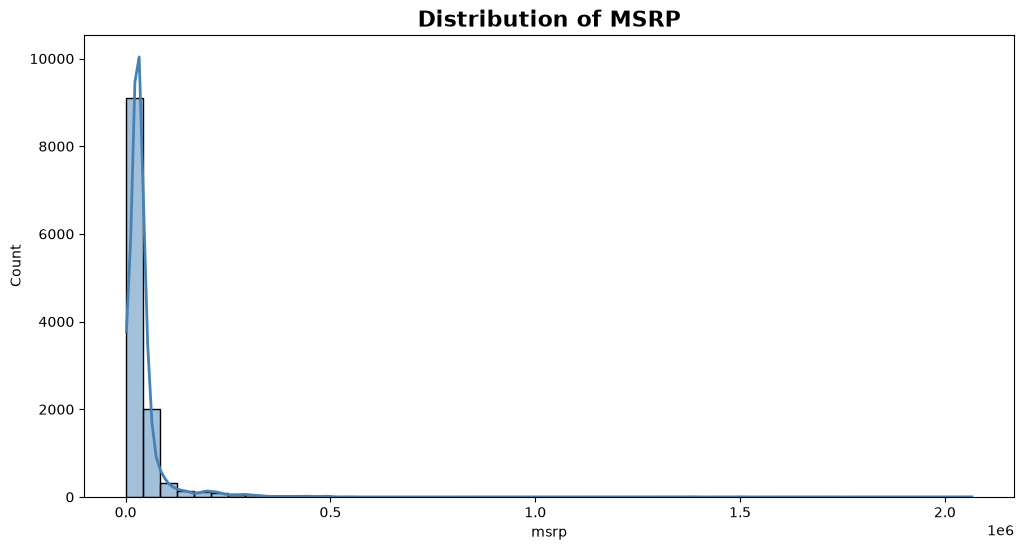

In [9]:
plt.figure(figsize=(12, 6))
sns.histplot(data=df, x="msrp", bins=50, kde=True, color="steelblue", line_kws={"color": "red", "linewidth": 2})
plt.title("Distribution of MSRP", fontsize=16, fontweight="bold")
plt.show()

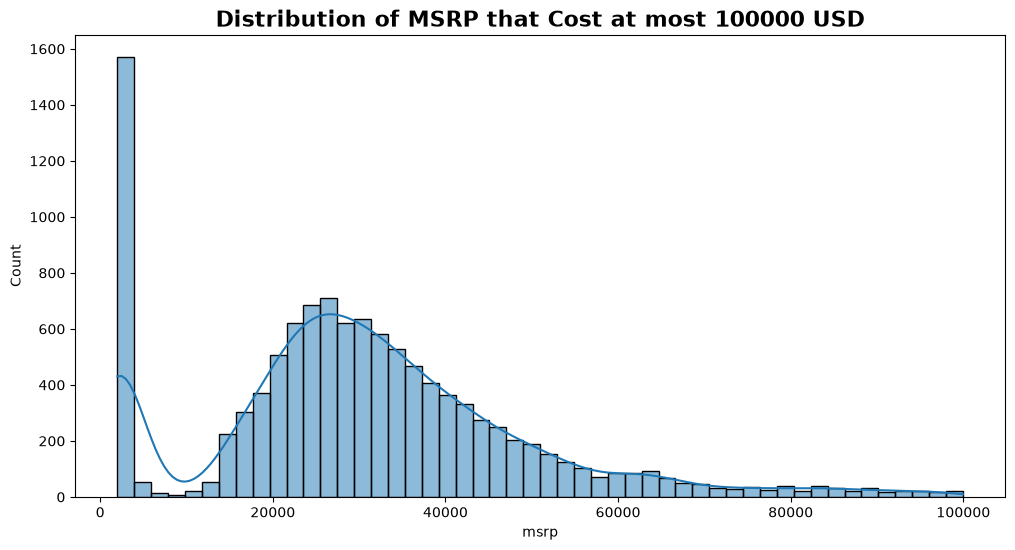

In [10]:
plt.figure(figsize=(12, 6))
sns.histplot(data=df.msrp[df.msrp < 100000], bins=50, kde=True)
plt.title(
    "Distribution of MSRP that Cost at most 100000 USD", fontsize=16, fontweight="bold"
)
plt.show()

---

 - Thanks to the upper plot we can see that there are **several cheaper cars**, but on the other hand there are so little and very expensive cars.

 - The first bar from the second plot shows us that several clients have set the lowest possible value on their cars. Which will tend to confuse the training of the model.

 - The second plot also shows a normal distribution tendency, without considering the first long bar.

---

In [11]:
df.msrp.describe()

count    1.191400e+04
mean     4.059474e+04
std      6.010910e+04
min      2.000000e+03
25%      2.100000e+04
50%      2.999500e+04
75%      4.223125e+04
max      2.065902e+06
Name: msrp, dtype: float64

<br>

---

## 2.2. Logarithmic Distribution


<br><br>

### 2.2.1. Logarithm `np.log(num)`

<br>

---

In [12]:
# We apply logarithms because we want to reduce outliers
# Example
outliers = np.array([1, 10, 100, 1000, 100_000, 1_000_000])
print(outliers)

np.log(outliers)

[      1      10     100    1000  100000 1000000]


array([ 0.        ,  2.30258509,  4.60517019,  6.90775528, 11.51292546,
       13.81551056])

In [13]:
# But if the outliers have "zero-values" we need to add 1 to the whole array
# otherwise we'll get MINUS INFINITE 
outliers_zero = np.array([0, 1, 10, 100, 1000, 100_000, 1_000_000])
print(outliers_zero)

np.log(outliers_zero)

[      0       1      10     100    1000  100000 1000000]


/tmp/ipykernel_16033/1963198112.py:6: RuntimeWarning: divide by zero encountered in log
  np.log(outliers_zero)


array([       -inf,  0.        ,  2.30258509,  4.60517019,  6.90775528,
       11.51292546, 13.81551056])

---

<br>

In [14]:
# NOTE: If we have  Zero values on the column we want to apply a logarithm.
# ...we need to add "1" to all the numpy array
new_outliers = outliers_zero + 1
print(new_outliers)

np.log(new_outliers)

[      1       2      11     101    1001  100001 1000001]


array([ 0.        ,  0.69314718,  2.39789527,  4.61512052,  6.90875478,
       11.51293546, 13.81551156])

<br><br>

### 2.2.2. Logarithm `np.log1p(num)`

<br>


>
>Return the natural logarithm of one plus the input array, element-wise.
>
>Calculates ``log(1 + x)``.
>


In [15]:
# Numpy 'log1p' helps us with arrays that have zero-values in it. It automatically add by 1 the whole array
np.log1p(outliers_zero)

array([ 0.        ,  0.69314718,  2.39789527,  4.61512052,  6.90875478,
       11.51293546, 13.81551156])

<br><br>

### 2.2.3. Apply Logarithm on `msrp`

<br>

---

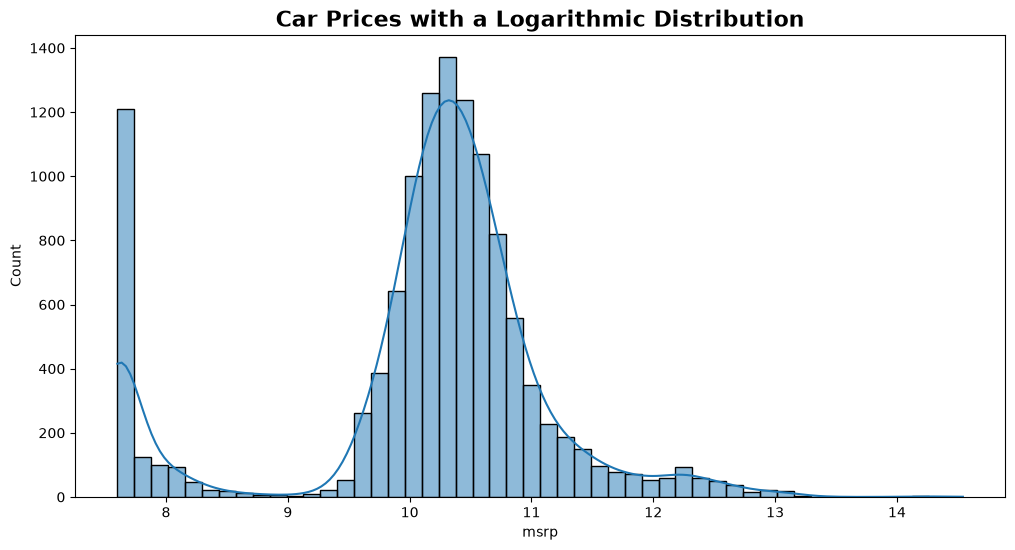

In [16]:
price_logs = np.log1p(df.msrp)

# Now we'll plot once again
plt.figure(figsize=(12, 6))
sns.histplot(price_logs, kde=True, bins=50)
plt.title('Car Prices with a Logarithmic Distribution', fontsize=16, fontweight='bold')
plt.show()

<br><br>

---

## 2.3. Missing Values

<br>

In [17]:
df.isna().sum()

make                    0
model                   0
year                    0
engine_fuel_type        3
engine_hp              69
engine_cylinders       30
transmission_type       0
driven_wheels           0
number_of_doors         6
market_category      3742
vehicle_size            0
vehicle_style           0
highway_mpg             0
city_mpg                0
popularity              0
msrp                    0
dtype: int64